In [29]:
print("Projet Barcode / QR Code")

Projet Barcode / QR Code


In [30]:
pip install opencv-python numpy matplotlib pyzbar

Note: you may need to restart the kernel to use updated packages.


In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("cv2 ok")

cv2 ok


In [32]:
import sys
print(sys.executable)

c:\Users\shop\anaconda3\python.exe


In [33]:
image_path = "../data/test1.png"

image = cv2.imread(image_path)

if image is None:
    print("Erreur : image non trouvée")
else:
    print("Image chargée avec succès")

Image chargée avec succès


In [34]:
import cv2
import numpy as np

In [35]:
image_path = "../data/test1.png"
image = cv2.imread(image_path)

print("Image chargée")

Image chargée


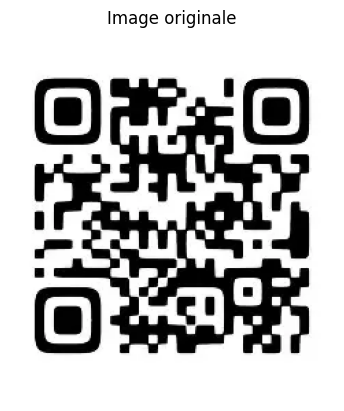

In [36]:
import matplotlib.pyplot as plt

# convertir BGR → RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.title("Image originale")
plt.axis("off")
plt.show()

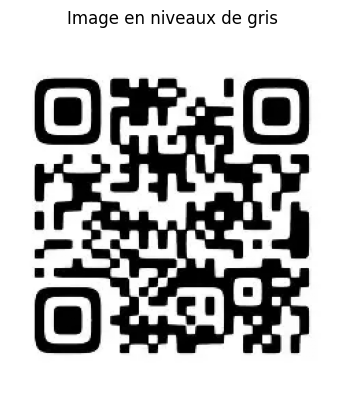

In [37]:
# conversion en grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap="gray")
plt.title("Image en niveaux de gris")
plt.axis("off")
plt.show()

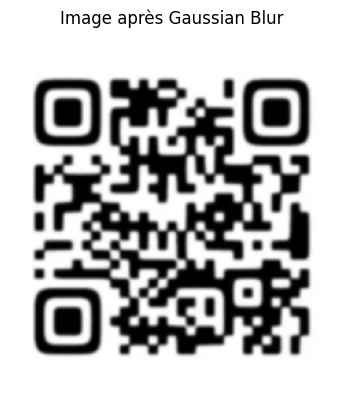

In [38]:
blur = cv2.GaussianBlur(gray, (5, 5), 0)

plt.imshow(blur, cmap="gray")
plt.title("Image après Gaussian Blur")
plt.axis("off")
plt.show()

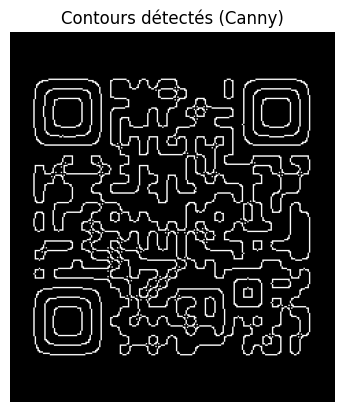

In [39]:
edges = cv2.Canny(blur, 50, 150)

plt.imshow(edges, cmap="gray")
plt.title("Contours détectés (Canny)")
plt.axis("off")
plt.show()

In [40]:
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

print("Nombre de contours détectés :", len(contours))

Nombre de contours détectés : 10


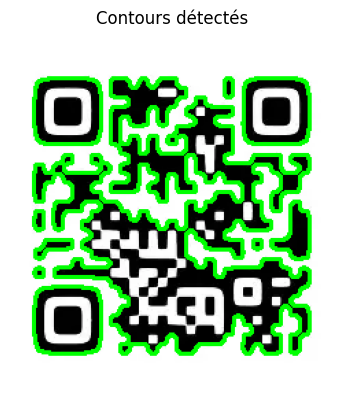

In [41]:
contour_image = image.copy()

cv2.drawContours(contour_image, contours, -1, (0,255,0), 2)

plt.imshow(cv2.cvtColor(contour_image, cv2.COLOR_BGR2RGB))
plt.title("Contours détectés")
plt.axis("off")
plt.show()

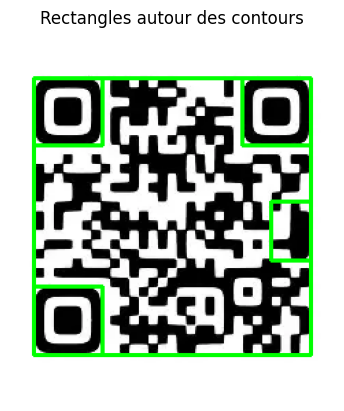

In [42]:
boxes_image = image.copy()

for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    
    # garder seulement les contours assez grands
    if w > 20 and h > 20:
        cv2.rectangle(boxes_image, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.imshow(cv2.cvtColor(boxes_image, cv2.COLOR_BGR2RGB))
plt.title("Rectangles autour des contours")
plt.axis("off")
plt.show()

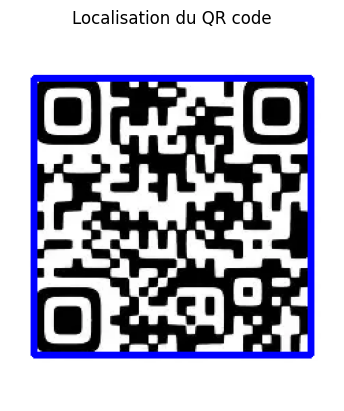

In [43]:
largest_contour = max(contours, key=cv2.contourArea)

x, y, w, h = cv2.boundingRect(largest_contour)

qr_box = image.copy()

cv2.rectangle(qr_box, (x, y), (x+w, y+h), (255, 0, 0), 3)

plt.imshow(cv2.cvtColor(qr_box, cv2.COLOR_BGR2RGB))
plt.title("Localisation du QR code")
plt.axis("off")
plt.show()

In [44]:
detector = cv2.QRCodeDetector()

data, points, _ = detector.detectAndDecode(image)

print("Contenu décodé :", data)

Contenu décodé : http://jensenart.co


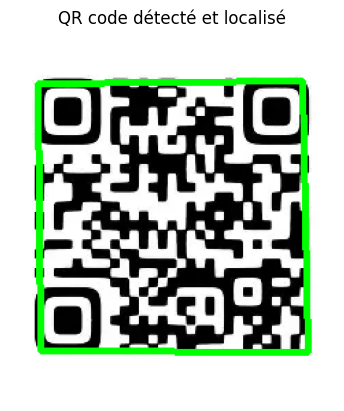

In [45]:
result_image = image.copy()

if points is not None:
    points = points.astype(int)
    
    for i in range(len(points[0])):
        pt1 = tuple(points[0][i])
        pt2 = tuple(points[0][(i + 1) % len(points[0])])
        cv2.line(result_image, pt1, pt2, (0, 255, 0), 3)

plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.title("QR code détecté et localisé")
plt.axis("off")
plt.show()

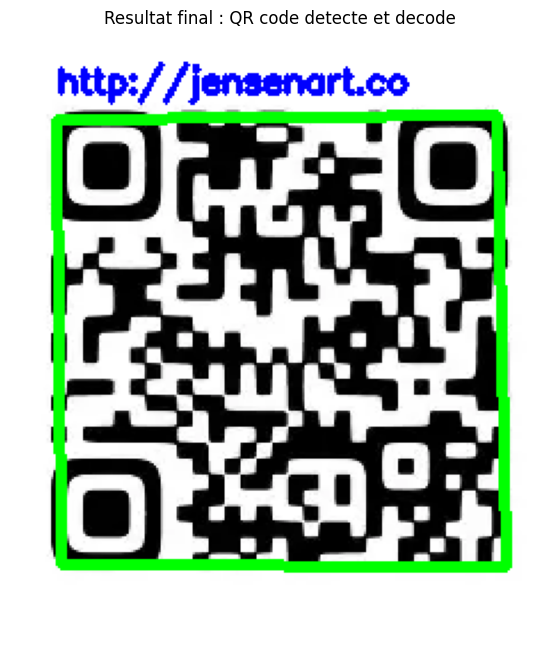

In [46]:
final_image = image.copy()

if points is not None:
    points = points.astype(int)

    for i in range(len(points[0])):
        pt1 = tuple(points[0][i])
        pt2 = tuple(points[0][(i + 1) % len(points[0])])
        cv2.line(final_image, pt1, pt2, (0, 255, 0), 3)

    x = points[0][:, 0].min()
    y = points[0][:, 1].min()

    cv2.putText(
        final_image,
        data,
        (x, y - 10 if y > 20 else y + 25),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.title("Resultat final : QR code detecte et decode")
plt.axis("off")
plt.show()

In [47]:
def scan_qr_image(image_path):
    import cv2
    import matplotlib.pyplot as plt

    image = cv2.imread(image_path)

    if image is None:
        print("Erreur : image non trouvée")
        return

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, 50, 150)

    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    detector = cv2.QRCodeDetector()
    data, points, _ = detector.detectAndDecode(image)

    final_image = image.copy()

    if points is not None and data != "":
        points = points.astype(int)

        for i in range(len(points[0])):
            pt1 = tuple(points[0][i])
            pt2 = tuple(points[0][(i + 1) % len(points[0])])
            cv2.line(final_image, pt1, pt2, (0, 255, 0), 3)

        x = points[0][:, 0].min()
        y = points[0][:, 1].min()

        cv2.putText(
            final_image,
            data,
            (x, y - 10 if y > 20 else y + 25),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            2
        )

        print("Contenu décodé :", data)

    else:
        print("Aucun QR code détecté ou décodé.")

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
    plt.title("Résultat du scanner QR")
    plt.axis("off")
    plt.show()

Contenu décodé : http://jensenart.co


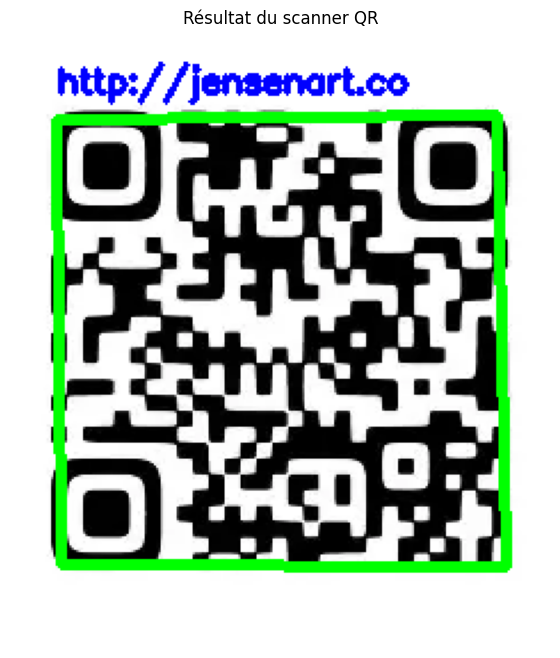

In [48]:
scan_qr_image("../data/test1.png")

Contenu décodé : a


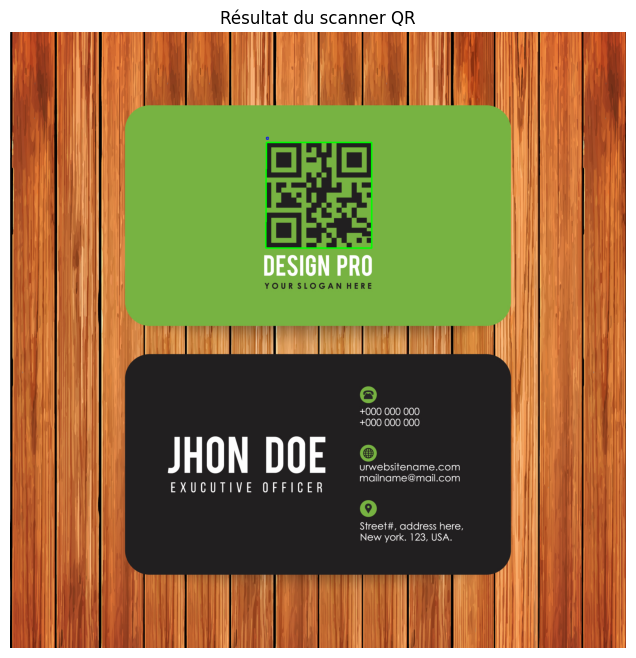

In [49]:
scan_qr_image("../data/test2.png")

In [50]:
import ipywidgets as widgets
print("ipywidgets ok")

ipywidgets ok


In [54]:
def scan_qr_image_clean(image_path):
    
    import cv2
    import matplotlib.pyplot as plt

    image = cv2.imread(image_path)

    if image is None:
        print("Erreur : image non trouvée")
        return

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5,5), 0)
    edges = cv2.Canny(blur, 50, 150)

    detector = cv2.QRCodeDetector()
    data, points, _ = detector.detectAndDecode(image)

    final_image = image.copy()

    if points is not None and data != "":
        points = points.astype(int)

        for i in range(len(points[0])):
            pt1 = tuple(points[0][i])
            pt2 = tuple(points[0][(i+1) % len(points[0])])
            cv2.line(final_image, pt1, pt2, (0,255,0), 3)

        x = int(points[0][:,0].min())
        y = int(points[0][:,1].min())

        cv2.putText(
            final_image,
            f"QR: {data}",
            (x, y-10 if y>20 else y+25),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255,0,0),
            2
        )

        print("QR code détecté")
        print("Contenu :", data)

    else:
        print("Aucun QR code détecté")

    plt.figure(figsize=(8,8))
    plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
    plt.title("Résultat du scanner QR")
    plt.axis("off")
    plt.show()

In [55]:
from IPython.display import display
import ipywidgets as widgets

# Liste des images disponibles
image_selector = widgets.Dropdown(
    options=["../data/test1.png", "../data/test2.png"],
    value="../data/test1.png",
    description="Image :"
)

# Bouton scanner
scan_button = widgets.Button(
    description="Scanner",
    button_style="success"
)

# Zone de sortie
output_area = widgets.Output()

# Fonction appelée quand on clique sur le bouton
def on_scan_button_clicked(b):
    with output_area:
        output_area.clear_output()
        scan_qr_image_clean(image_selector.value)

# Associer bouton et fonction
scan_button.on_click(on_scan_button_clicked)

# Afficher l'interface
display(image_selector, scan_button, output_area)

Dropdown(description='Image :', options=('../data/test1.png', '../data/test2.png'), value='../data/test1.png')

Button(button_style='success', description='Scanner', style=ButtonStyle())

Output()

In [56]:
from IPython.display import display
import ipywidgets as widgets

image_selector = widgets.Dropdown(
    options=["../data/test1.png", "../data/test2.png", "../data/no_qr.png"],
    value="../data/test1.png",
    description="Image :"
)

scan_button = widgets.Button(
    description="Scanner",
    button_style="success"
)

output_area = widgets.Output()

def on_scan_button_clicked(b):
    with output_area:
        output_area.clear_output()
        scan_qr_image_clean(image_selector.value)

scan_button.on_click(on_scan_button_clicked)

display(image_selector, scan_button, output_area)

Dropdown(description='Image :', options=('../data/test1.png', '../data/test2.png', '../data/no_qr.png'), value…

Button(button_style='success', description='Scanner', style=ButtonStyle())

Output()

In [60]:
def scan_all_codes(image_path):
    
    import cv2
    import matplotlib.pyplot as plt

    image = cv2.imread(image_path)

    if image is None:
        print("Erreur : image non trouvée")
        return

    output = image.copy()

    # -------- QR CODE --------
    qr_detector = cv2.QRCodeDetector()
    data, points, _ = qr_detector.detectAndDecode(image)

    if points is not None and data != "":
        points = points.astype(int)

        for i in range(len(points[0])):
            pt1 = tuple(points[0][i])
            pt2 = tuple(points[0][(i+1) % len(points[0])])
            cv2.line(output, pt1, pt2, (0,255,0), 3)

        print("QR Code détecté :", data)

    # -------- BARCODE --------
    barcode_detector = cv2.barcode_BarcodeDetector()
    decoded_info, decoded_type, corners = barcode_detector.detectAndDecode(image)

    if decoded_info:

        for i in range(len(decoded_info)):

            pts = corners[i].astype(int)

            for j in range(4):
                pt1 = tuple(pts[j])
                pt2 = tuple(pts[(j+1)%4])
                cv2.line(output, pt1, pt2, (255,0,0), 3)

            print("Barcode détecté :", decoded_info[i])

    if not decoded_info and (points is None or data==""):
        print("Aucun code détecté")

    plt.figure(figsize=(8,8))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Detection QR + Barcode")
    plt.show()

QR Code détecté : http://jensenart.co


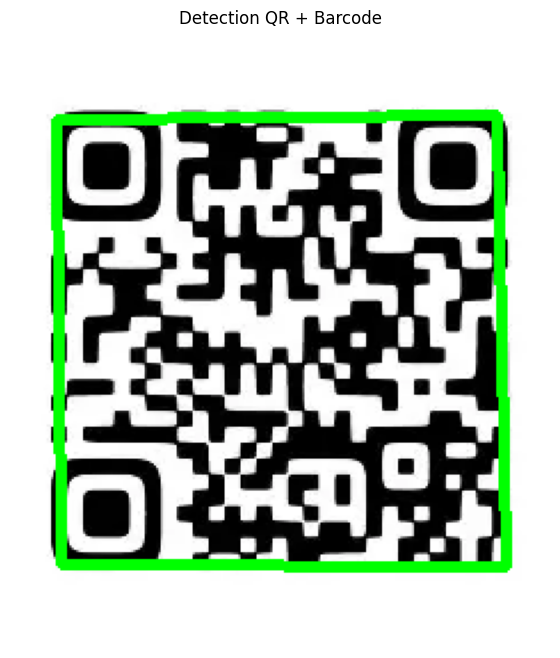

In [61]:
scan_all_codes("../data/test1.png")

Aucun code détecté


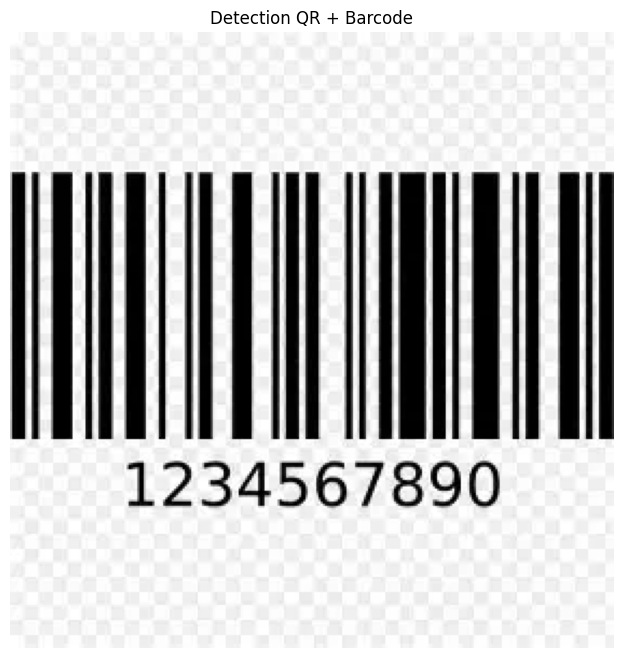

In [62]:
scan_all_codes("../data/barcode1.png")

In [64]:
def scan_all_codes(image_path):
    
    import cv2
    import matplotlib.pyplot as plt

    image = cv2.imread(image_path)

    if image is None:
        print("Erreur : image non trouvée")
        return

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    output = image.copy()

    detected_any = False

    # -------- QR CODE --------
    qr_detector = cv2.QRCodeDetector()
    data, points, _ = qr_detector.detectAndDecode(image)

    if points is not None and data != "":
        detected_any = True
        points = points.astype(int)

        for i in range(len(points[0])):
            pt1 = tuple(points[0][i])
            pt2 = tuple(points[0][(i + 1) % len(points[0])])
            cv2.line(output, pt1, pt2, (0, 255, 0), 3)

        print("QR Code détecté :", data)

    # -------- BARCODE --------
    barcode_detector = cv2.barcode_BarcodeDetector()
    decoded_info, decoded_type, corners = barcode_detector.detectAndDecode(gray)

    if decoded_info:
        detected_any = True

        for i in range(len(decoded_info)):
            pts = corners[i].astype(int)

            for j in range(4):
                pt1 = tuple(pts[j])
                pt2 = tuple(pts[(j + 1) % 4])
                cv2.line(output, pt1, pt2, (255, 0, 0), 3)

            print("Barcode détecté :", decoded_info[i])

    if not detected_any:
        print("Aucun code détecté")

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Detection QR + Barcode")
    plt.show()

Aucun code détecté


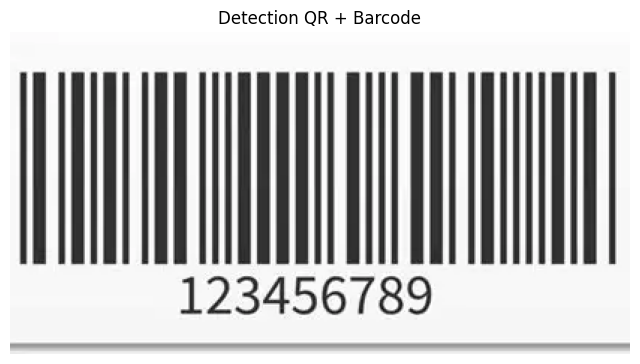

In [65]:
scan_all_codes("../data/barcode2.png")

In [66]:
def detect_barcode_region(image_path):
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt

    image = cv2.imread(image_path)

    if image is None:
        print("Erreur : image non trouvée")
        return

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Gradient selon x pour faire ressortir les barres verticales
    grad_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    grad_x = cv2.convertScaleAbs(grad_x)

    # Binarisation
    _, thresh = cv2.threshold(grad_x, 50, 255, cv2.THRESH_BINARY)

    # Fermeture morphologique pour relier les barres
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (21, 7))
    closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    # Quelques opérations pour nettoyer
    closed = cv2.erode(closed, None, iterations=2)
    closed = cv2.dilate(closed, None, iterations=2)

    # Trouver les contours
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    output = image.copy()

    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)

        cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 3)
        print("Barcode localisé")
        print(f"Bounding box: x={x}, y={y}, w={w}, h={h}")
    else:
        print("Aucun barcode localisé")

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(grad_x, cmap="gray")
    plt.title("Gradient X")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(thresh, cmap="gray")
    plt.title("Threshold")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(closed, cmap="gray")
    plt.title("Morphology")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title("Barcode localisé")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

Barcode localisé
Bounding box: x=0, y=25, w=414, h=166


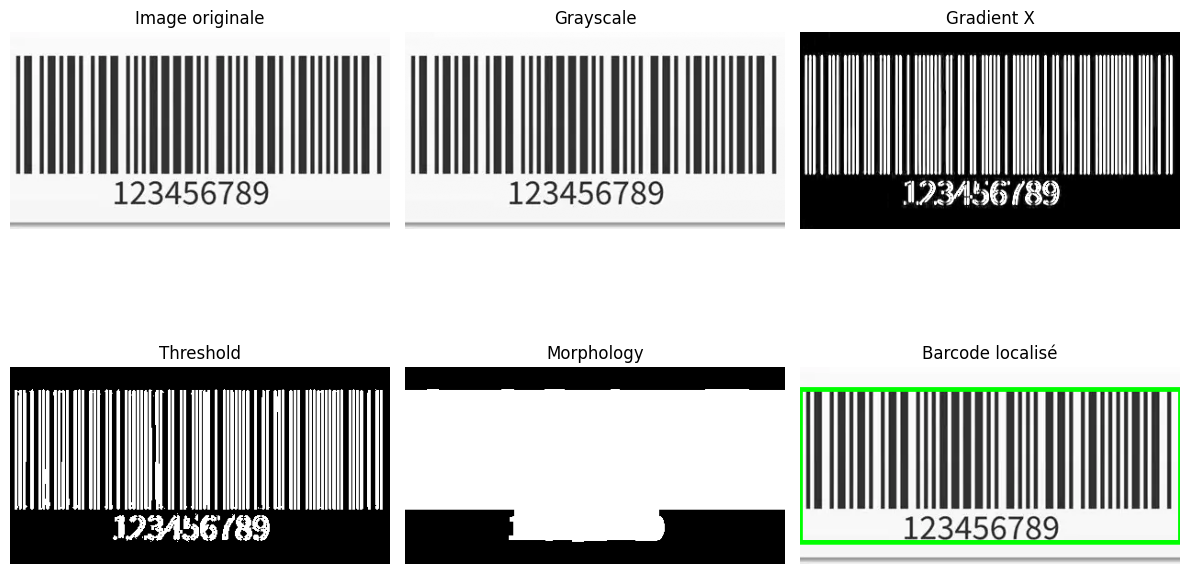

In [67]:
detect_barcode_region("../data/barcode2.png")

Barcode localisé
Bounding box: x=0, y=0, w=1200, h=1200


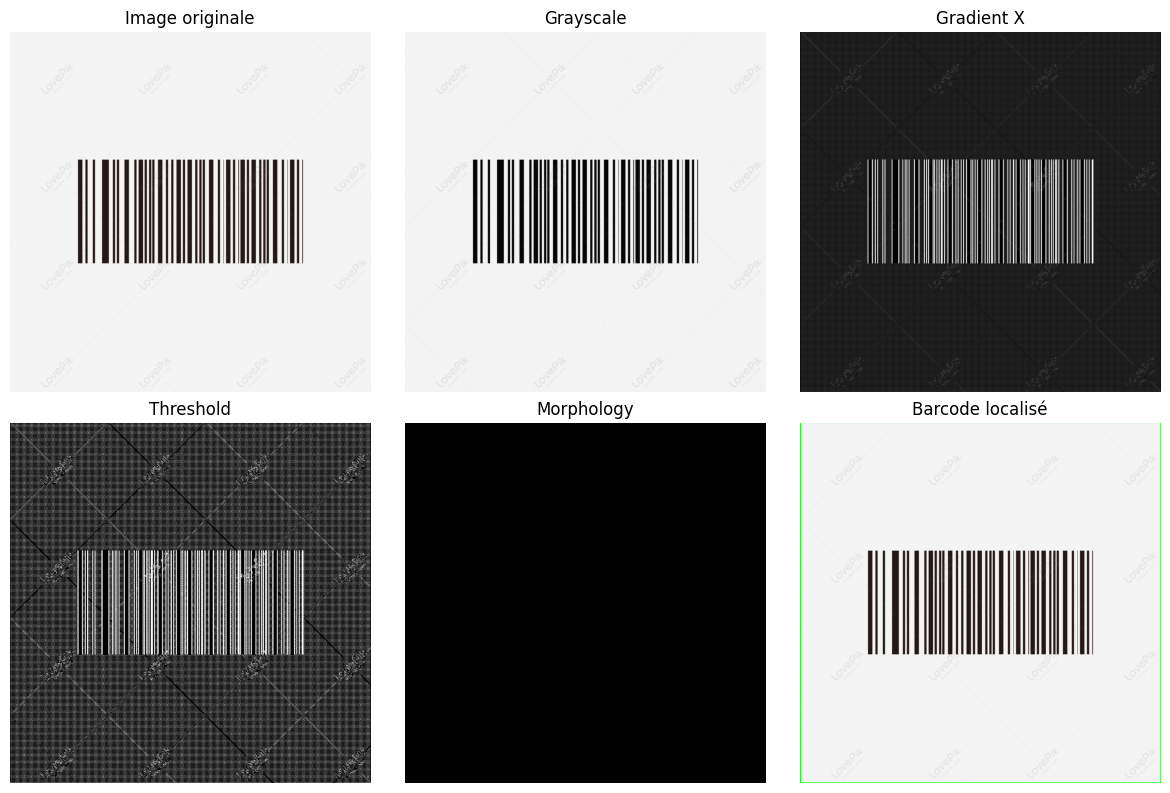

In [68]:
detect_barcode_region("../data/barcode3.png")

Barcode localisé
Bounding box: x=87, y=61, w=317, h=213


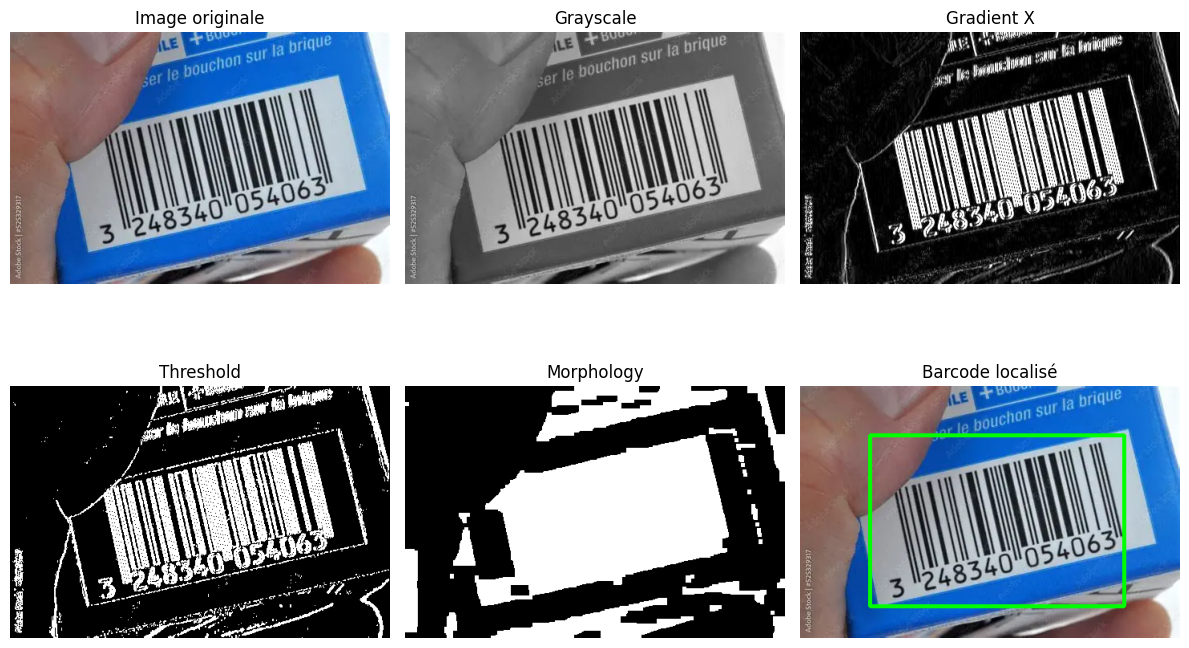

In [69]:
detect_barcode_region("../data/barcode.png")

In [71]:
def detect_barcode_region(image_path):
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt

    image = cv2.imread(image_path)

    if image is None:
        print("Erreur : image non trouvée")
        return

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Gradient selon x pour mettre en valeur les barres verticales
    grad_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    grad_x = cv2.convertScaleAbs(grad_x)

    # Binarisation
    _, thresh = cv2.threshold(grad_x, 50, 255, cv2.THRESH_BINARY)

    # Fermeture morphologique pour regrouper les barres
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (21, 7))
    closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    # Nettoyage
    closed = cv2.erode(closed, None, iterations=2)
    closed = cv2.dilate(closed, None, iterations=2)

    # Recherche des contours
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    output = image.copy()

    barcode_found = False

    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)

        # Filtre géométrique pour éviter de confondre avec un QR code
        ratio = w / float(h)

        if ratio > 2.0:
            barcode_found = True
            cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 3)
            print("Barcode localisé")
            print(f"Bounding box: x={x}, y={y}, w={w}, h={h}")
            print(f"Ratio largeur/hauteur: {ratio:.2f}")
        else:
            print("Région rejetée : probablement un QR code ou une forme non valide")
            print(f"Ratio largeur/hauteur: {ratio:.2f}")
    else:
        print("Aucun contour détecté")

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(grad_x, cmap="gray")
    plt.title("Gradient X")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(thresh, cmap="gray")
    plt.title("Threshold")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(closed, cmap="gray")
    plt.title("Morphology")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    if barcode_found:
        plt.title("Barcode localisé")
    else:
        plt.title("Aucun barcode valide")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [76]:
def detect_barcode_region(image_path):
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt

    image = cv2.imread(image_path)

    if image is None:
        print("Erreur : image non trouvée")
        return

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Gradient horizontal pour faire ressortir les barres verticales
    grad_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    grad_x = cv2.convertScaleAbs(grad_x)

    # Binarisation
    _, thresh = cv2.threshold(grad_x, 50, 255, cv2.THRESH_BINARY)

    # Fermeture morphologique horizontale
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 7))
    closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    # Nettoyage
    closed = cv2.erode(closed, None, iterations=1)
    closed = cv2.dilate(closed, None, iterations=2)

    # Contours externes
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    output = image.copy()

    best_box = None
    best_score = -1

    image_area = image.shape[0] * image.shape[1]

    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        area = w * h
        ratio = w / float(h) if h != 0 else 0

        # Filtres barcode plus souples
        if area < 0.03 * image_area:
            continue
        if ratio < 1.2:
            continue

        # Score simple : grande aire + forme allongée
        score = area * ratio

        if score > best_score:
            best_score = score
            best_box = (x, y, w, h, ratio)

    if best_box is not None:
        x, y, w, h, ratio = best_box
        cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 3)
        print("Barcode localisé")
        print(f"Bounding box: x={x}, y={y}, w={w}, h={h}")
        print(f"Ratio largeur/hauteur: {ratio:.2f}")
    else:
        print("Aucun barcode valide détecté")

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(grad_x, cmap="gray")
    plt.title("Gradient X")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(thresh, cmap="gray")
    plt.title("Threshold")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(closed, cmap="gray")
    plt.title("Morphology")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title("Résultat barcode")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

Barcode localisé
Bounding box: x=54, y=0, w=420, h=279
Ratio largeur/hauteur: 1.51


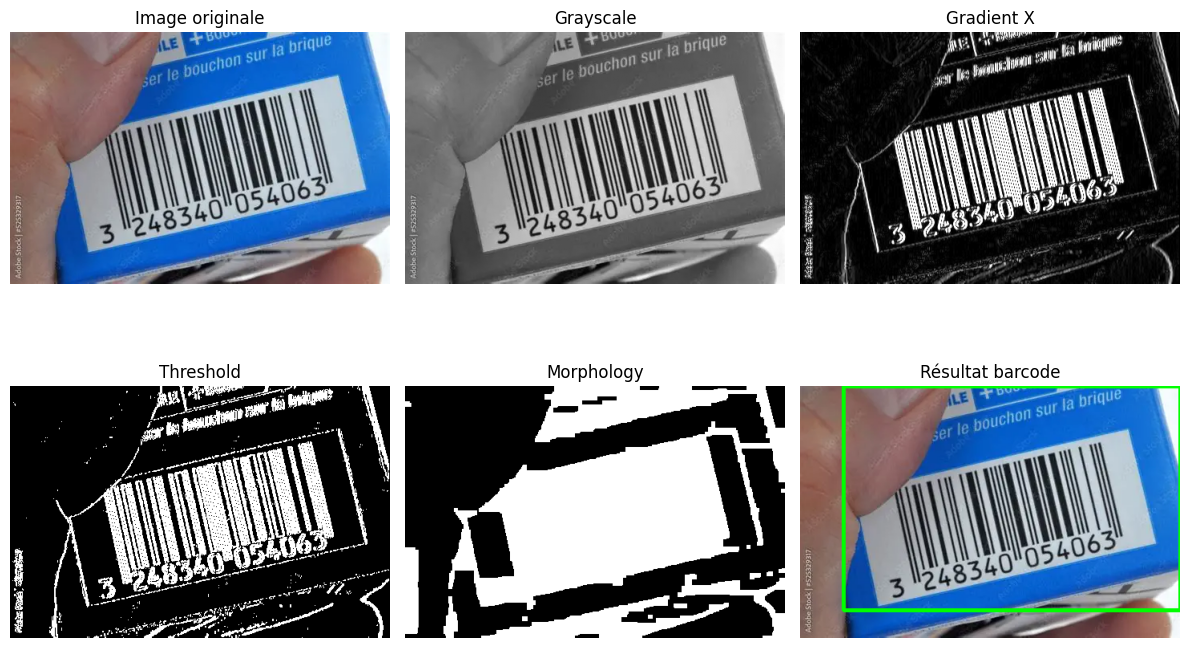

In [77]:
detect_barcode_region("../data/barcode.png")

Aucun barcode valide détecté


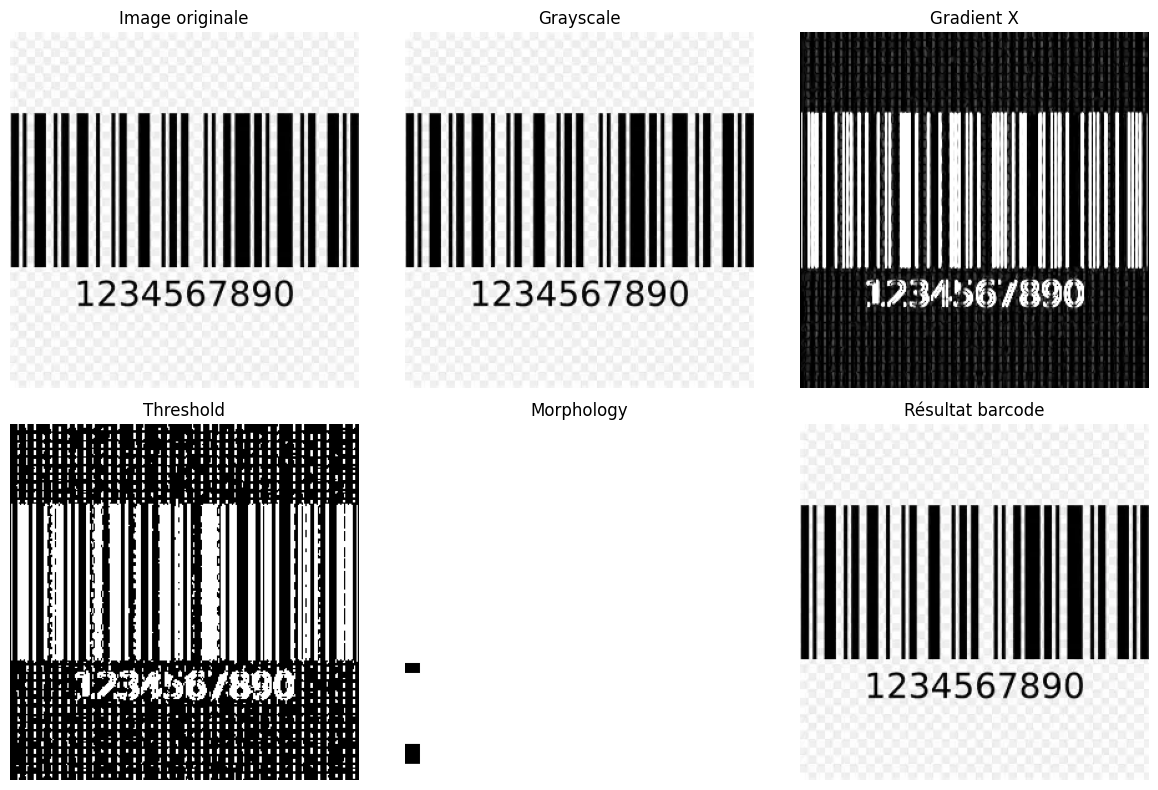

In [78]:
detect_barcode_region("../data/barcode1.png")

In [79]:
from IPython.display import display
import ipywidgets as widgets

# Liste des images
image_selector = widgets.Dropdown(
    options=[
        "../data/test1.png",
        "../data/test2.png",
        "../data/no_qr.png",
        "../data/barcode.png",
        "../data/barcode1.png",
        "../data/barcode2.png"
    ],
    value="../data/test1.png",
    description="Image :",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

# Choix du type de détection
mode_selector = widgets.Dropdown(
    options=["QR Code", "Barcode"],
    value="QR Code",
    description="Mode :",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="250px")
)

# Bouton
scan_button = widgets.Button(
    description="Scanner",
    button_style="success",
    layout=widgets.Layout(width="150px", height="40px")
)

# Zone d'affichage
output_area = widgets.Output()

def on_scan_button_clicked(b):
    with output_area:
        output_area.clear_output()

        image_path = image_selector.value
        mode = mode_selector.value

        print(f"Image choisie : {image_path}")
        print(f"Mode choisi : {mode}")
        print("-" * 50)

        if mode == "QR Code":
            scan_qr_image_clean(image_path)
        elif mode == "Barcode":
            detect_barcode_region(image_path)

scan_button.on_click(on_scan_button_clicked)

display(
    widgets.VBox([
        image_selector,
        mode_selector,
        scan_button,
        output_area
    ])
)